# Module 6 Lab 3: Textbook Appendix C, Retrieve and Search

**CS 82A - Introduction to Data Science**

**Ramisha Tasfia**

**GitHub:** [https://github.com/ramishatasfia5156-commits/cs82a-coursework/blob/main/module6/module6_lab3.ipynb](https://github.com/ramishatasfia5156-commits/cs82a-coursework/blob/main/module6/module6_lab3.ipynb)

**Source:** Appendix C, sections C.3 and C.4. I reproduced the book's retrieval and search patterns on the customers table from Lab 2.

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

con = sqlite3.connect("lab3.db")
con.execute("DROP TABLE IF EXISTS customers")
con.execute("""
CREATE TABLE customers (
    id            INTEGER PRIMARY KEY,
    name          TEXT NOT NULL,
    city          TEXT,
    signup_year   INTEGER,
    total_spent   REAL
)
""")
con.execute("""
INSERT INTO customers (name, city, signup_year, total_spent) VALUES
    ('Nova Quill',    'Santa Monica', 2021, 412.50),
    ('Juniper Vale',  'Culver City',  2022, 138.25),
    ('Orion Pike',    'Venice',       2023, 889.00),
    ('Sable Hartwell','Inglewood',    2020, 57.80),
    ('Marlow Finch',  'Los Angeles',  2024, 1204.99),
    ('Tamsin Reeve',  'Torrance',     2022, 301.10),
    ('Ellis Moreau',  'Santa Monica', 2025, 76.40),
    ('Wren Calloway', 'Culver City',  2021, 640.00)
""")
con.commit()
print("Rows in customers:", con.execute("SELECT COUNT(*) FROM customers").fetchone()[0])

Rows in customers: 8


**Filtered retrieval (where):** customers who spent more than 300

In [2]:
pd.read_sql("select * from customers where total_spent > 300", con)

,id,name,city,signup_year,total_spent
0,1,Nova Quill,Santa Monica,2021,412.50
1,3,Orion Pike,Venice,2023,889.00
2,5,Marlow Finch,Los Angeles,2024,1204.99
3,6,Tamsin Reeve,Torrance,2022,301.10
4,8,Wren Calloway,Culver City,2021,640.00


**Sorting (order by):** every customer, newest signup first

In [3]:
pd.read_sql("select name, signup_year from customers order by signup_year desc", con)

,name,signup_year
0,Ellis Moreau,2025
1,Marlow Finch,2024
2,Orion Pike,2023
3,Juniper Vale,2022
4,Tamsin Reeve,2022
5,Nova Quill,2021
6,Wren Calloway,2021
7,Sable Hartwell,2020


**Text search (like):** names containing the letters ll

In [4]:
pd.read_sql("select * from customers where name like '%ll%'", con)

,id,name,city,signup_year,total_spent
0,1,Nova Quill,Santa Monica,2021,412.5
1,4,Sable Hartwell,Inglewood,2020,57.8
2,7,Ellis Moreau,Santa Monica,2025,76.4
3,8,Wren Calloway,Culver City,2021,640.0


**Query to chart:** total spent per city

,city,total_spent
0,Los Angeles,1204.99
1,Venice,889.00
2,Culver City,778.25
3,Santa Monica,488.90
4,Torrance,301.10
5,Inglewood,57.80


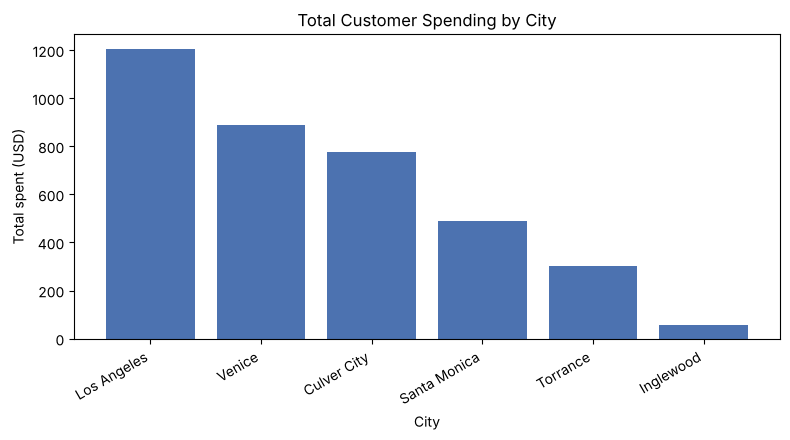

In [5]:
df = pd.read_sql("""
select city, sum(total_spent) as total_spent
from customers
group by city
order by total_spent desc
""", con)
display(df)

plt.figure(figsize=(8, 4.5))
plt.bar(df["city"], df["total_spent"], color="#4C72B0")
plt.title("Total Customer Spending by City")
plt.xlabel("City")
plt.ylabel("Total spent (USD)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## AI Disclosure
Claude (Anthropic) was used to help with SQL syntax and to verify that my queries returned the correct rows. I chose the search term and the chart, and I reviewed every line.

Key prompt: "Do my WHERE, ORDER BY, and LIKE queries return the right rows?"